In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [34]:
data = pd.DataFrame({
    "Date": [
        '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05',
        '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-11',
        '2026-09-12', '2026-09-14', '2026-09-16', '2026-09-17', '2026-09-19',
        '2026-09-21', '2026-09-22', '2026-09-24', '2026-09-25', '2026-09-26',
        '2026-09-27', '2026-09-28', '2026-10-01', '2026-10-03', '2026-10-05',
        '2026-10-06', '2026-10-07', '2026-10-09', '2026-10-11', '2026-10-12',
        '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-17', '2026-10-20',
        '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25',
        '2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29', '2026-10-30',
        '2026-10-31'
],

    "Activity Type": [
        'Walking', 'Running', 'Yoga', 'Walking', 'Gym',
        'Swimming', 'Yoga', 'Gym', 'Running', 'Yoga',
        'Gym', 'Walking', 'Swimming', 'Gym', 'Cycling',
        'Swimming', 'Swimming', 'Swimming', 'Yoga', 'Swimming',
        'Walking', 'Running', 'Gym', 'Cycling', 'Running',
        'Swimming', 'Cycling', 'Walking', 'Walking', 'Yoga',
        'Running', 'Running', 'Gym', 'Yoga', 'Gym',
        'Gym', 'Running', 'Gym', 'Cycling', 'Running',
        'Cycling', 'Gym', 'Walking', 'Walking', 'Running',
        'Walking'
],

    "Duration (Minutes)": [
        55, 30, 50, 30, 50,
        60, 60, 55, 40, 40,
        30, 35, 30, 65, 60,
        40, 30, 60, 45, 35,
        20, 45, 65, 35, 25,
        40, 40, 40, 35, 55,
        40, 40, 50, 55, 45,
        55, 45, 45, 85, 30,
        85, 70, 35, 55, 40,
        50
],

    "Calories Burned": [
        243, 306, 169, 120, 325,
        571, 181, 324, 377, 127,
        183, 132, 290, 434, 450,
        328, 251, 549, 149, 298,
        91, 410, 460, 246, 255,
        351, 272, 162, 133, 181,
        408, 393, 342, 158, 310,
        378, 404, 273, 646, 310,
        639, 477, 158, 211, 414,
        217
]
})

data.to_csv("fitness_activities.csv", index=False)

print(data.head(10))
print("\nTotal records:", len(data))
print("Fitness activities dataset created successfully!")

         Date Activity Type  Duration (Minutes)  Calories Burned
0  2026-09-01       Walking                  55              243
1  2026-09-02       Running                  30              306
2  2026-09-03          Yoga                  50              169
3  2026-09-04       Walking                  30              120
4  2026-09-05           Gym                  50              325
5  2026-09-06      Swimming                  60              571
6  2026-09-07          Yoga                  60              181
7  2026-09-08           Gym                  55              324
8  2026-09-09       Running                  40              377
9  2026-09-11          Yoga                  40              127

Total records: 46
Fitness activities dataset created successfully!


In [35]:
FILE_NAME = "fitness_activities.csv"

COLUMNS = ["Date", "Activity Type", "Duration (Minutes)", "Calories Burned"]

ACTIVITY_LIST = ["Running", "Yoga", "Cycling", "Swimming", "Walking", "Gym", "Dancing"]

print("Activities available:", ACTIVITY_LIST)

Activities available: ['Running', 'Yoga', 'Cycling', 'Swimming', 'Walking', 'Gym', 'Dancing']


In [36]:
class FitnessTracker:

    def __init__(self, filename):
        self.filename = filename
        self.df = self.load_data()

    def load_data(self):
        if not os.path.exists(self.filename):
            print("File not found. Starting with an empty dataset.")
            return pd.DataFrame(columns=COLUMNS + ["Calories per Minute"])

        try:
            df = pd.read_csv(self.filename)
        except pd.errors.EmptyDataError:
            print("File is empty. Starting with an empty dataset.")
            return pd.DataFrame(columns=COLUMNS + ["Calories per Minute"])

        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df["Duration (Minutes)"] = pd.to_numeric(df["Duration (Minutes)"], errors="coerce")
        df["Calories Burned"] = pd.to_numeric(df["Calories Burned"], errors="coerce")

        df = df.drop_duplicates()
        df = df.dropna()

        df = df[(df["Duration (Minutes)"] > 0) & (df["Calories Burned"] > 0)]
        df = df.reset_index(drop=True)

        df["Calories per Minute"] = (
            df["Calories Burned"] / df["Duration (Minutes)"]
        ).round(2)

        print("Data loaded and cleaned successfully!")
        return df

    def save_data(self):
        out = self.df[COLUMNS].copy()
        out["Date"] = pd.to_datetime(out["Date"]).dt.strftime("%Y-%m-%d")
        out.to_csv(self.filename, index=False)

    def log_activity(self, activity_type, duration, calories, date=None):

        
        if duration <= 0 or calories <= 0:
            print("Invalid input! Duration and calories must be positive.")
            return

        if date is None:
            date = pd.Timestamp.today().normalize()

        new_row = {
            "Date": pd.Timestamp(date),
            "Activity Type": activity_type.title(),
            "Duration (Minutes)": duration,
            "Calories Burned": calories,
            "Calories per Minute": round(calories / duration, 2)
        }

        self.df = pd.concat(
            [self.df, pd.DataFrame([new_row])],
            ignore_index=True
        )

        self.df["Date"] = pd.to_datetime(self.df["Date"])

        self.save_data()
        print("Activity logged successfully!")

    def calculate_metrics(self):
        if self.df.empty:
            print("No data available to calculate metrics.")
            return

        calories = self.df["Calories Burned"].to_numpy()
        duration = self.df["Duration (Minutes)"].to_numpy()

        print("\n----- Fitness Metrics -----")
        print("Total Activities:", len(self.df))
        print("Total Calories Burned:", np.sum(calories))
        print("Average Duration:", round(np.mean(duration), 2), "minutes")
        print("Average Calories per Activity:", round(np.mean(calories), 2))
        print("Longest Workout:", np.max(duration), "minutes")

        daily = self.df.groupby("Date")["Calories Burned"].sum().to_numpy()
        print("Daily Average Calories:", round(np.mean(daily), 2))

        print("\nActivity Frequency:")
        print(self.df["Activity Type"].value_counts())

        self.percentage_improvement()

    def percentage_improvement(self):
        weekly = self.weekly_trends()

        if len(weekly) < 2:
            print("\nNot enough weeks of data to calculate improvement.")
            return

        values = weekly["Calories Burned"].to_numpy()
        first_half, second_half = np.array_split(values, 2)

        old_avg = np.mean(first_half)
        new_avg = np.mean(second_half)

        improvement = ((new_avg - old_avg) / old_avg) * 100
        print("\nWeekly Calories Improvement (first half vs second half):",
              round(improvement, 2), "%")

    def filter_activities(self, condition):
        result = self.df.copy()

        if "type" in condition:
            result = result[
                result["Activity Type"].str.lower() == condition["type"].lower()
            ]

        if "start" in condition:
            result = result[result["Date"] >= pd.to_datetime(condition["start"])]

        if "end" in condition:
            result = result[result["Date"] <= pd.to_datetime(condition["end"])]

        return result

    def time_per_activity(self):
        return self.df.groupby("Activity Type")["Duration (Minutes)"].sum()

    def group_by_duration(self):
        groups = pd.cut(
            self.df["Duration (Minutes)"],
            bins=[0, 30, 45, np.inf],
            labels=["Short (up to 30 min)", "Medium (31-45 min)", "Long (over 45 min)"]
        )
        return self.df.groupby(groups, observed=True)["Calories Burned"].agg(
            ["count", "mean"]
        ).round(2).rename(columns={"count": "Workouts", "mean": "Avg Calories"})

    def weekly_trends(self):
        weekly = self.df.set_index("Date").resample("W")[
            ["Duration (Minutes)", "Calories Burned"]
        ].sum()
        return weekly[weekly["Calories Burned"] > 0]

    def generate_report(self):
        if self.df.empty:
            print("No data available to generate a report.")
            return

        print("\n===== Fitness Report =====")
        print("Period:", self.df["Date"].min().date(), "to", self.df["Date"].max().date())

        print("\nTotal Time Spent per Activity (minutes):")
        print(self.time_per_activity())

        print("\nTotal Calories per Activity:")
        print(self.df.groupby("Activity Type")["Calories Burned"].sum())

        print("\nAverage Calories per Minute by Activity:")
        print(self.df.groupby("Activity Type")["Calories per Minute"].mean().round(2))

        print("\nWorkouts Grouped by Duration:")
        print(self.group_by_duration())

        print("\nWeekly Trends:")
        print(self.weekly_trends())

        best = self.df.loc[self.df["Calories Burned"].idxmax()]
        print("\nBest Workout:", best["Activity Type"], "on",
              best["Date"].date(), "-", best["Calories Burned"], "calories")


    def plot_bar_chart(self):
        if self.df.empty:
            print("No data to plot.")
            return

        time_data = self.time_per_activity().reset_index()

        plt.figure(figsize=(8, 5))
        sns.barplot(
            data=time_data,
            x="Activity Type",
            y="Duration (Minutes)",
            hue="Activity Type",
            palette="viridis",
            legend=True
        )
        plt.title("Time Spent on Each Activity")
        plt.xlabel("Activity Type")
        plt.ylabel("Total Duration (Minutes)")
        plt.xticks(rotation=30)
        plt.legend(title="Activity Type", fontsize=8)
        plt.tight_layout()
        plt.savefig("bar_chart.png")
        plt.show()

    def plot_line_graph(self):
        if self.df.empty:
            print("No data to plot.")
            return

        daily = self.df.groupby("Date")["Calories Burned"].sum()

        plt.figure(figsize=(9, 5))
        plt.plot(daily.index, daily.values, marker="o",
                 color="green", label="Calories Burned")
        plt.title("Calories Burned Over Time")
        plt.xlabel("Date")
        plt.ylabel("Calories Burned")
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig("line_graph.png")
        plt.show()

    def plot_pie_chart(self):
        if self.df.empty:
            print("No data to plot.")
            return

        counts = self.df["Activity Type"].value_counts()

        plt.figure(figsize=(7, 7))
        plt.pie(
            counts,
            labels=counts.index,
            autopct="%1.1f%%",
            startangle=90
        )
        plt.title("Activity Distribution")
        plt.legend(counts.index, title="Activities", loc="best")
        plt.tight_layout()
        plt.savefig("pie_chart.png")
        plt.show()

    def plot_heatmap(self):
        if len(self.df) < 2:
            print("Need at least 2 records to draw a heatmap.")
            return

        correlation = self.df[
            ["Duration (Minutes)", "Calories Burned", "Calories per Minute"]
        ].corr()

        plt.figure(figsize=(7, 5))
        sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
        plt.title("Correlation: Duration vs Calories Burned")
        plt.tight_layout()
        plt.savefig("heatmap.png")
        plt.show()

    def show_all_charts(self):
        self.plot_bar_chart()
        self.plot_line_graph()
        self.plot_pie_chart()
        self.plot_heatmap()

In [8]:
tracker = FitnessTracker(FILE_NAME)

print("\nFitness tracker object created successfully!")
tracker.df

Data loaded and cleaned successfully!

Fitness tracker object created successfully!


,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
0,2026-09-01,Walking,55,243,4.42
1,2026-09-02,Running,30,306,10.20
2,2026-09-03,Yoga,50,169,3.38
3,2026-09-04,Walking,30,120,4.00
4,2026-09-05,Gym,50,325,6.50
5,2026-09-06,Swimming,60,571,9.52
6,2026-09-07,Yoga,60,181,3.02
7,2026-09-08,Gym,55,324,5.89
8,2026-09-09,Running,40,377,9.43
9,2026-09-11,Yoga,40,127,3.18


In [9]:
print("Shape of data:", tracker.df.shape)
print()
print(tracker.df.dtypes)
print()
print("Missing values:")
print(tracker.df.isnull().sum())

Shape of data: (46, 5)

Date                   datetime64[us]
Activity Type                     str
Duration (Minutes)              int64
Calories Burned                 int64
Calories per Minute           float64
dtype: object

Missing values:
Date                   0
Activity Type          0
Duration (Minutes)     0
Calories Burned        0
Calories per Minute    0
dtype: int64


In [ ]:
tracker.log_activity("Running", 40, 380, "2026-11-01")

Activity logged successfully!


In [ ]:
tracker.log_activity("Yoga", -20, 150)
tracker.log_activity("Cycling", 30, 0)

Invalid input! Duration and calories must be positive.
Invalid input! Duration and calories must be positive.


In [ ]:
tracker.df.tail(3)

,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
44,2026-10-30,Running,40,414,10.35
45,2026-10-31,Walking,50,217,4.34
46,2026-11-01,Running,40,380,9.50


In [13]:
tracker.calculate_metrics()


----- Fitness Metrics -----
Total Activities: 47
Total Calories Burned: 14486
Average Duration: 46.06 minutes
Average Calories per Activity: 308.21
Longest Workout: 85 minutes
Daily Average Calories: 308.21

Activity Frequency:
Activity Type
Running     10
Gym         10
Walking      9
Swimming     7
Yoga         6
Cycling      5
Name: count, dtype: int64

Weekly Calories Improvement (first half vs second half): 33.16 %


In [ ]:
running = tracker.filter_activities({"type": "Running"})
print("Running activities:", len(running))
running

Running activities: 10


,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
1,2026-09-02,Running,30,306,10.20
8,2026-09-09,Running,40,377,9.43
21,2026-09-28,Running,45,410,9.11
24,2026-10-05,Running,25,255,10.20
30,2026-10-13,Running,40,408,10.20
31,2026-10-14,Running,40,393,9.82
36,2026-10-22,Running,45,404,8.98
39,2026-10-25,Running,30,310,10.33
44,2026-10-30,Running,40,414,10.35
46,2026-11-01,Running,40,380,9.50


In [ ]:
october = tracker.filter_activities({"start": "2026-10-01", "end": "2026-10-31"})
print("Activities in October:", len(october))
october

Activities in October: 24


,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
22,2026-10-01,Gym,65,460,7.08
23,2026-10-03,Cycling,35,246,7.03
24,2026-10-05,Running,25,255,10.20
25,2026-10-06,Swimming,40,351,8.78
26,2026-10-07,Cycling,40,272,6.80
27,2026-10-09,Walking,40,162,4.05
28,2026-10-11,Walking,35,133,3.80
29,2026-10-12,Yoga,55,181,3.29
30,2026-10-13,Running,40,408,10.20
31,2026-10-14,Running,40,393,9.82


In [ ]:
yoga_oct = tracker.filter_activities({"type": "Yoga", "start": "2026-10-01", "end": "2026-10-31"})
yoga_oct

,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
29,2026-10-12,Yoga,55,181,3.29
33,2026-10-17,Yoga,55,158,2.87


In [17]:
tracker.generate_report()


===== Fitness Report =====
Period: 2026-09-01 to 2026-11-01

Total Time Spent per Activity (minutes):
Activity Type
Cycling     305
Gym         530
Running     375
Swimming    295
Walking     355
Yoga        305
Name: Duration (Minutes), dtype: int64

Total Calories per Activity:
Activity Type
Cycling     2253
Gym         3506
Running     3657
Swimming    2638
Walking     1467
Yoga         965
Name: Calories Burned, dtype: int64

Average Calories per Minute by Activity:
Activity Type
Cycling     7.29
Gym         6.57
Running     9.81
Swimming    8.89
Walking     4.14
Yoga        3.18
Name: Calories per Minute, dtype: float64

Workouts Grouped by Duration:
                      Workouts  Avg Calories
Duration (Minutes)                          
Short (up to 30 min)         8        225.75
Medium (31-45 min)          20        286.25
Long (over 45 min)          19        366.05

Weekly Trends:
            Duration (Minutes)  Calories Burned
Date                                          

In [18]:
calories = tracker.df["Calories Burned"].to_numpy()

print("Average Calories:", round(np.mean(calories), 2))
print("Maximum Calories:", np.max(calories))
print("Minimum Calories:", np.min(calories))
print("Standard Deviation:", round(np.std(calories), 2))

Average Calories: 308.21
Maximum Calories: 646
Minimum Calories: 91
Standard Deviation: 136.52


In [ ]:
time_data = tracker.time_per_activity()
percent = (time_data.to_numpy() / np.sum(time_data.to_numpy())) * 100

for name, p in zip(time_data.index, percent):
    print(f"{name}: {round(p, 2)}%")

Cycling: 14.09%
Gym: 24.48%
Running: 17.32%
Swimming: 13.63%
Walking: 16.4%
Yoga: 14.09%


In [ ]:
tracker.time_per_activity()

Activity Type
Cycling     305
Gym         530
Running     375
Swimming    295
Walking     355
Yoga        305
Name: Duration (Minutes), dtype: int64

In [ ]:
tracker.group_by_duration()

,Workouts,Avg Calories
Duration (Minutes),,
Short (up to 30 min),8,225.75
Medium (31-45 min),20,286.25
Long (over 45 min),19,366.05


In [ ]:
tracker.weekly_trends()

,Duration (Minutes),Calories Burned
Date,,
2026-09-06,275,1734
2026-09-13,225,1192
2026-09-20,190,1306
2026-09-27,230,1666
2026-10-04,145,1116
2026-10-11,180,1173
2026-10-18,240,1482
2026-10-25,305,2321
2026-11-01,375,2496


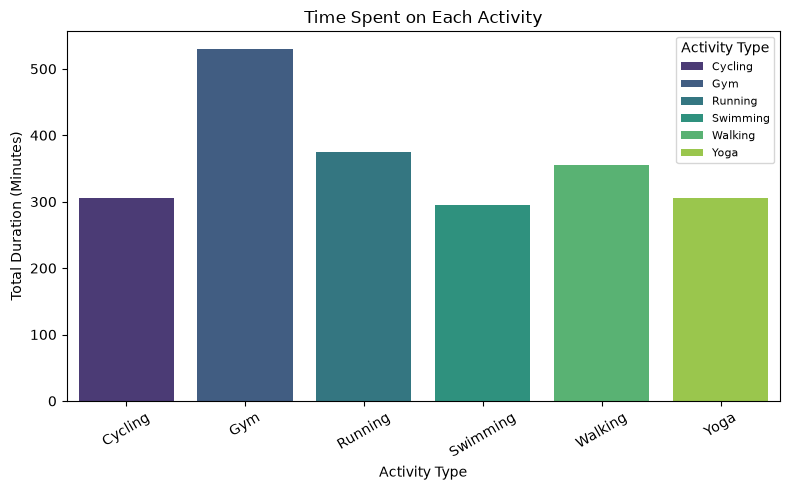

In [23]:
tracker.plot_bar_chart()

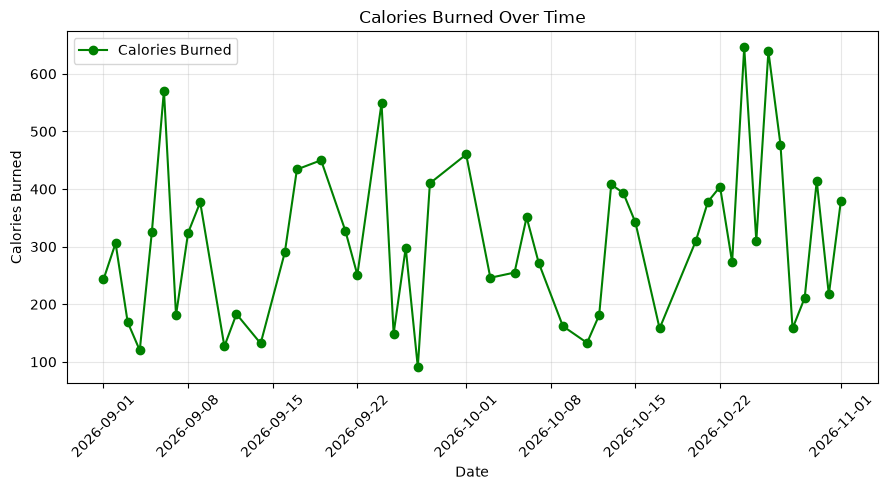

In [22]:
tracker.plot_line_graph()

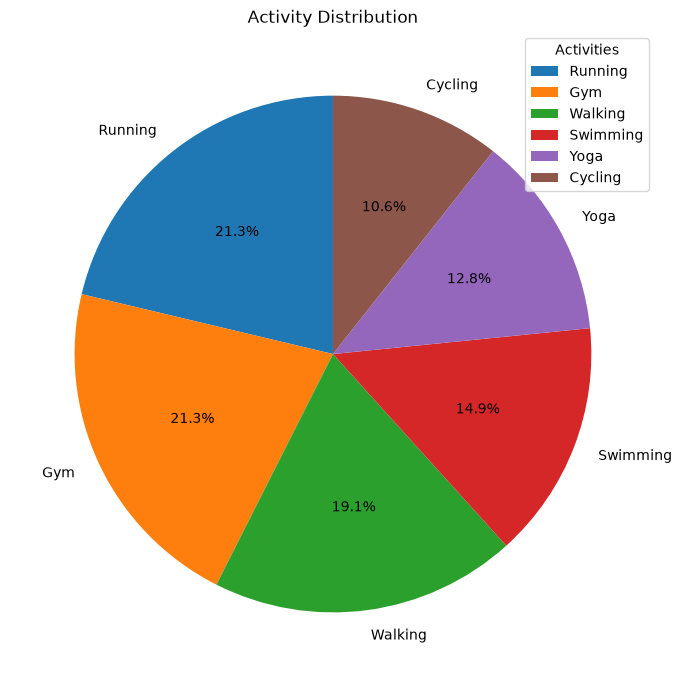

In [21]:
tracker.plot_pie_chart()

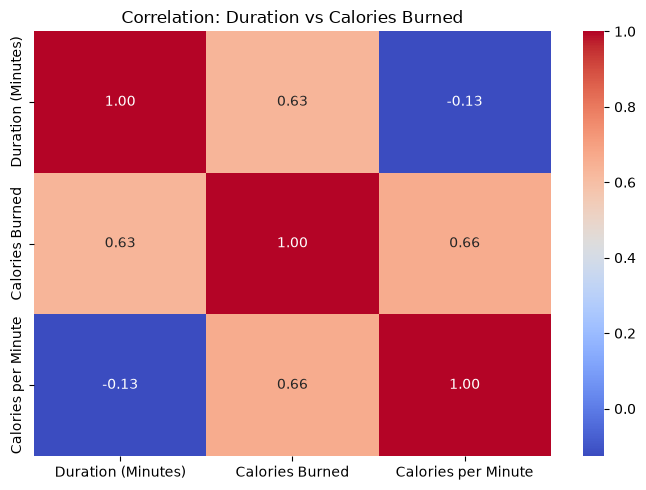

In [20]:
tracker.plot_heatmap()

In [27]:
empty_tracker = FitnessTracker("no_such_file.csv")

empty_tracker.calculate_metrics()
empty_tracker.generate_report()
empty_tracker.plot_bar_chart()

File not found. Starting with an empty dataset.
No data available to calculate metrics.
No data available to generate a report.
No data to plot.


In [ ]:

def get_positive_number(message):
    while True:
        value = input(message)
        try:
            number = float(value)
            if number > 0:
                return int(number) if number.is_integer() else number
            print("Please enter a number greater than 0.")
        except ValueError:
            print("Invalid input! Please enter a number.")


def get_date(message, allow_blank=True):
    while True:
        value = input(message).strip()
        if value == "" and allow_blank:
            return None
        try:
            return pd.to_datetime(value, format="%Y-%m-%d")
        except ValueError:
            print("Invalid date! Use YYYY-MM-DD format.")



def get_activity():
    print("\nAvailable activities:")
    for i, activity in enumerate(ACTIVITY_LIST, start=1):
        print(f"  {i}. {activity}")
    print(f"  {len(ACTIVITY_LIST) + 1}. Other (type your own)")

    while True:
        choice = input("Choose activity number: ").strip()

        if choice.isdigit():
            choice = int(choice)
            if 1 <= choice <= len(ACTIVITY_LIST):
                return ACTIVITY_LIST[choice - 1]
            if choice == len(ACTIVITY_LIST) + 1:
                name = input("Enter activity name: ").strip()
                if name != "" and name.replace(" ", "").isalpha():
                    return name.title()
                print("Activity name should contain only letters.")
                continue
        print("Invalid choice! Try again.")

In [29]:
def log_activity_menu(tracker):
    print("\n--- Log New Activity ---")
    activity = get_activity()
    duration = get_positive_number("Enter duration (minutes): ")
    calories = get_positive_number("Enter calories burned: ")
    date = get_date("Enter date (YYYY-MM-DD) or press Enter for today: ")
    tracker.log_activity(activity, duration, calories, date)

print("Input functions ready!")

Input functions ready!


In [32]:

log_activity_menu(tracker)


--- Log New Activity ---

Available activities:
  1. Running
  2. Yoga
  3. Cycling
  4. Swimming
  5. Walking
  6. Gym
  7. Dancing
  8. Other (type your own)
Invalid choice! Try again.
Activity logged successfully!


In [31]:

tracker.df.tail()

,Date,Activity Type,Duration (Minutes),Calories Burned,Calories per Minute
42,2026-10-28,Walking,35,158,4.51
43,2026-10-29,Walking,55,211,3.84
44,2026-10-30,Running,40,414,10.35
45,2026-10-31,Walking,50,217,4.34
46,2026-11-01,Running,40,380,9.50
